# Netflix Global Content Performance Strategy
Author: Violetta Kalinicheva  
Date: October 28, 2026  
Modified by: Violetta Kalinicheva

## 1. Audience, question, and decision
For a content analytics team: how do peak weekly reach, repeated Global Top 10 appearances, and country breadth differ in a fixed historical snapshot? The decision is how to construct a balanced review shortlist without mistaking chart popularity for subscriber retention, profitability, or artistic quality.

I keep show title and season together. Views comparisons use only the 44-week views-reporting period, June 18, 2023–April 14, 2024. Each title-season receives one vote in persistence summaries. I do not multiply maximum views by cumulative weeks into an unsupported 'performance score'.

In [1]:
# I audit the two weekly source grains and any optional historical appendix.
from analysis import (load_and_audit, summarize, plot_persistence, plot_peaks,
                      plot_breadth, plot_tradeoff, save_validation)
from IPython.display import display, Markdown
import pandas as pd
import matplotlib.pyplot as plt
global_data, countries, popular, metadata = load_and_audit()
display(pd.DataFrame(metadata['audit']).T)
print({k:v for k,v in metadata.items() if k not in ['audit','source_sha256']})

,downloaded_rows,rows_after_time_boundary,columns,exact_duplicates,season_missing_rows_after_time_boundary
all-weeks-global-netflix.xlsx,11080,5840,9,0,2992
all-weeks-countries-netflix.xlsx,515920,272260,8,0,138772


{'global_rows': 5840, 'country_rows': 272260, 'most_popular_rows': 0, 'countries': 94, 'schedule_flags_available': False, 'optional_91day_appendix_available': False, 'weeks': 146, 'first_week': '2021-07-04', 'last_week': '2024-04-14', 'views_first_week': '2023-06-18', 'views_period_rows': 1760, 'views_period_weeks': 44, 'views_period_zero_runtime_rows': 72, 'hours_only_rows': 4080, 'runtime_views_rounding_max_relative_difference_pct': 7.6956214037354975, 'global_title_season_units': 2113, 'ambiguous_country_title_week_rows': 6, 'views_period_ambiguous_country_title_week_rows': 0}


## Data fitness and transformations
The default workflow downloads the two current official weekly workbooks locally and bounds them to July 4, 2021–April 14, 2024. The bounded data include 5,840 Global title-week rows and 272,260 country title-week rows, spanning 146 weeks and 94 countries overall. Country coverage varies between 93 and 94 by week. No exact rows are duplicated. Six historical country rows have an ambiguous 'The Mummy' title-week label at different ranks. They are retained in the audit and excluded from title-identified country summaries; none falls in the selected views window. Names do not guarantee stable content identifiers across remakes.

There are 4,080 hours-only Global rows before June 18, 2023. They are not assigned invented views. The views-era file contains 72 zero runtimes. I treat those runtimes as unavailable for independent hours/runtime checks and keep Netflix's published view counts unchanged. Missing season labels become empty season keys only for grouping. Each country-week-category-rank remains unique.

The Most Popular 91-day list is an optional historical appendix, not required for this release's two-file core. It is unavailable in the default run because a current all-time list cannot recreate a historical ranking. Likewise, the current Global download omits old staggered-launch fields. No missing schedule flags are interpreted as proof of a simultaneous release. Reported views are hours divided by runtime, not distinct people.

,title_season_units,median_observed_weeks,mean_observed_weeks,median_peak_weekly_views
category,,,,
Films (English),222,1.0,1.982,5150000.0
Films (Non-English),198,2.0,2.222,2450000.0
TV (English),173,2.0,2.543,3300000.0
TV (Non-English),148,2.0,2.973,2600000.0


""


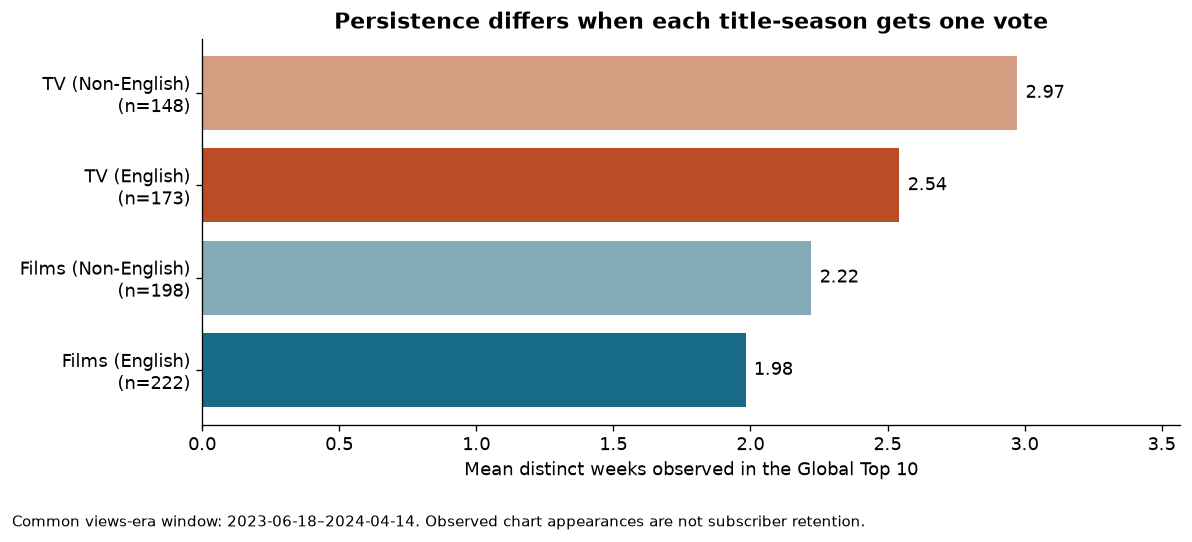

In [2]:
# I aggregate one title-season at a time within the common reporting window.
units, category_summary, peaks, breadth, most_popular, coverage, metrics = summarize(
    global_data, countries, popular, metadata)
display(category_summary.round(3))
display(pd.DataFrame(metrics['category_summary_excluding_staggered_launch_units']).round(3))
plot_persistence(category_summary)
plt.show()

### Visualization 1 interpretation and sensitivity
There are 741 title-season units in the common window. Mean observed Global Top 10 weeks are 1.98 for English films, 2.22 for non-English films, 2.54 for English TV, and 2.97 for non-English TV. Medians are 1, 2, 2, and 2 respectively, so the mean difference does not describe every title. Release schedules may affect apparent persistence. Because the current publisher download omits staggered-launch fields, this public-download run cannot separate that influence. The code reports the fields as unavailable rather than inventing flags.

Observation-window boundaries, catalog availability, and Top 10 selection prevent a causal language comparison. Appearing for more weeks is not evidence that the same subscribers stayed subscribed.

,category,display_title,peak_weekly_views,observed_weeks
32,Films (English),Damsel,50800000.0,5
78,Films (English),Leave the World Behind,44900000.0,5
44,Films (English),Extraction 2,42800000.0,7
468,TV (English),Fool Me Once: Limited Series,37100000.0,8
82,Films (English),Lift,36700000.0,5
60,Films (English),Heart of Stone,35200000.0,5
79,Films (English),Leo,34600000.0,10
125,Films (English),Rebel Moon — Part One: A Child of Fire,34000000.0,4
342,Films (Non-English),Nowhere,29900000.0,15
188,Films (English),The Out-Laws,28600000.0,4


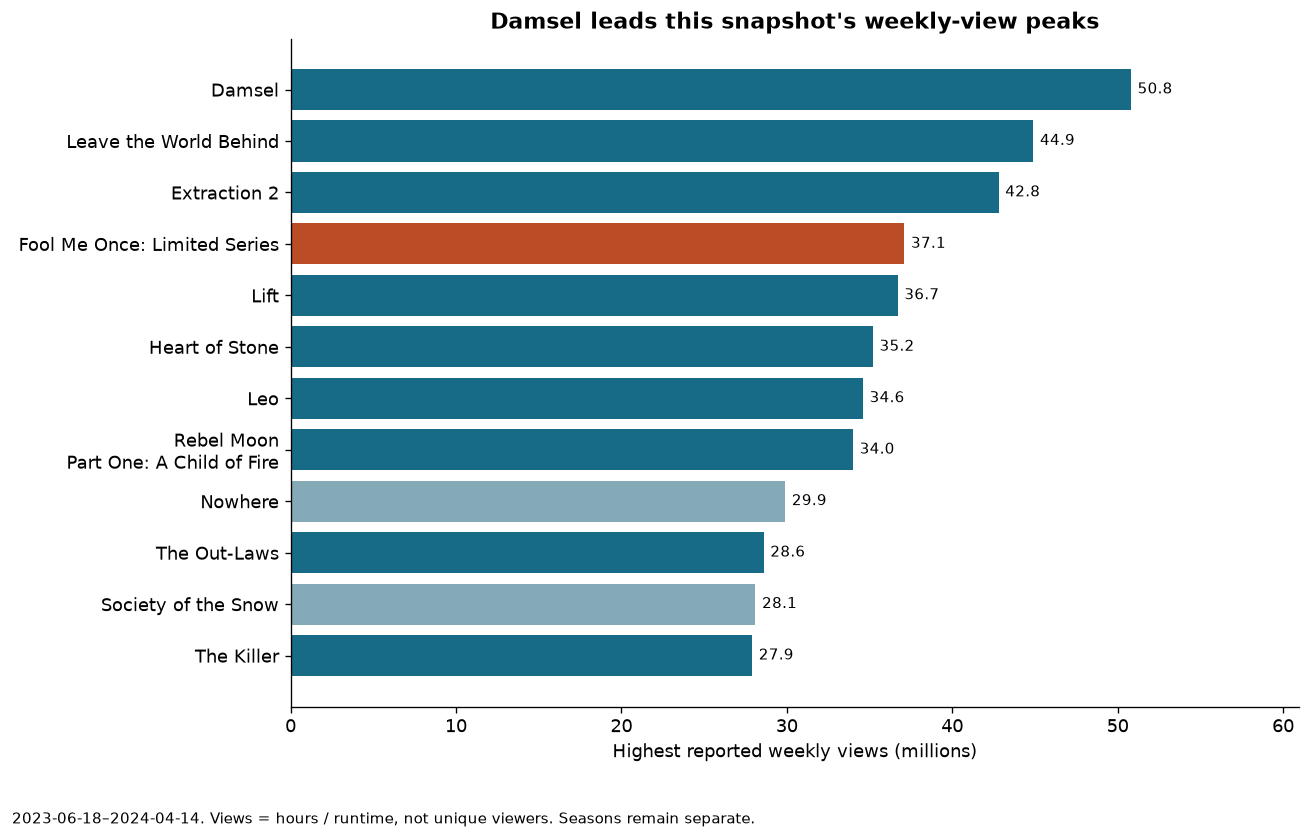

In [3]:
# I keep peak reach separate from persistence instead of inventing a combined score.
display(peaks[['category','display_title','peak_weekly_views','observed_weeks']])
plot_peaks(peaks)
plt.show()

### Visualization 2 interpretation
Damsel has the highest observed weekly view peak, 50.8 million, in this views-era snapshot. Eleven of the top 12 peak entries are films. These are peaks among charting entries, not an average treatment effect of producing a film. Published counts are rounded and may include repeat viewing.

,category,display_title,countries,country_week_appearances
2796,TV,ONE PIECE: Season 1,93,543
515,Films,Extraction 2,93,468
940,Films,Leave the World Behind,93,438
382,Films,Damsel,93,409
1537,Films,Society of the Snow,93,408
711,Films,Heart of Stone,93,402
960,Films,Lift,93,391
944,Films,Leo,93,390
1218,Films,Nowhere,93,366
2244,TV,3 Body Problem: Season 1,93,361


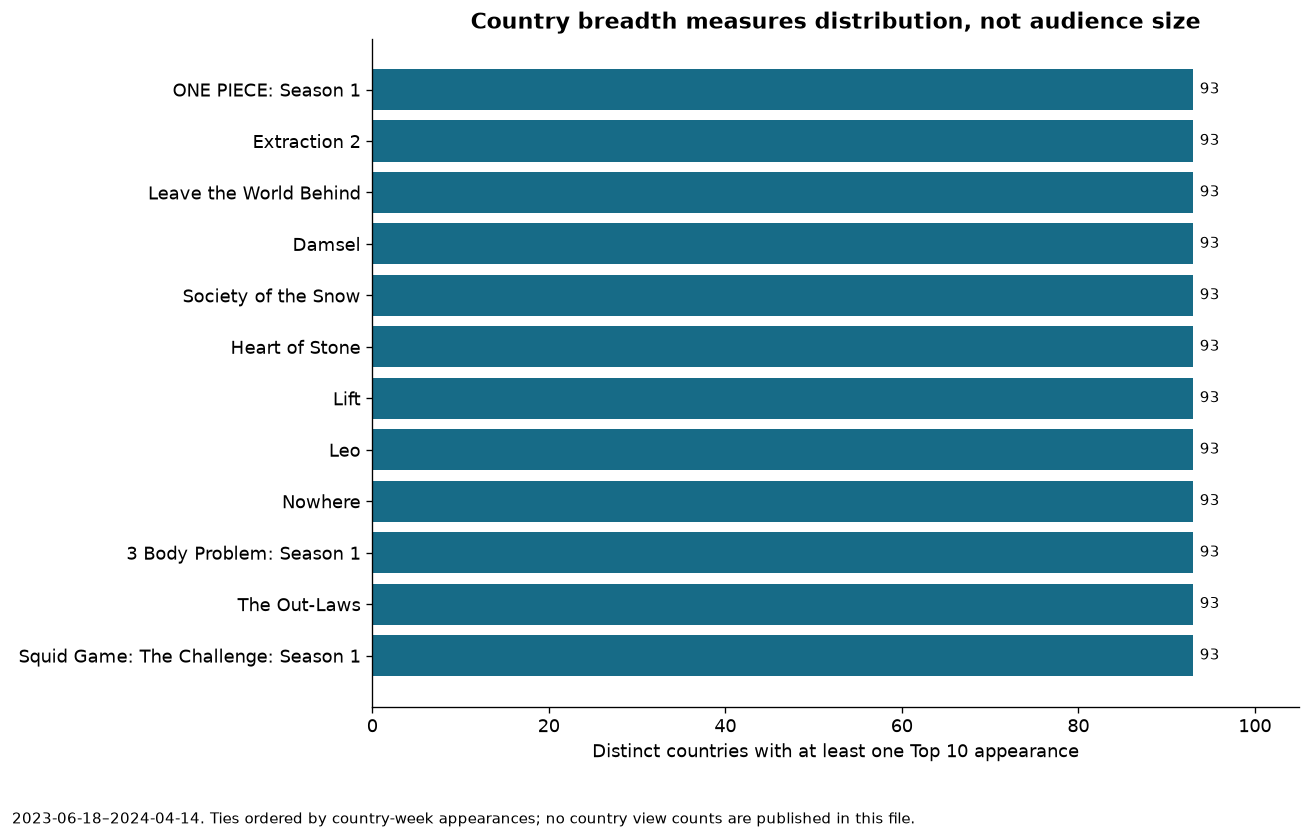

In [4]:
# I count countries, not country rows, when discussing geographic breadth.
display(breadth[['category','display_title','countries','country_week_appearances']])
plot_breadth(breadth)
plt.show()

### Visualization 3 interpretation
ONE PIECE: Season 1 appears in 93 countries during the common window and has 543 country-week appearances. Many titles tie on country count, so the chart uses appearances only to order ties. A title's presence in a small and a large country counts equally. These rankings do not contain country view totals and do not measure population-weighted reach.

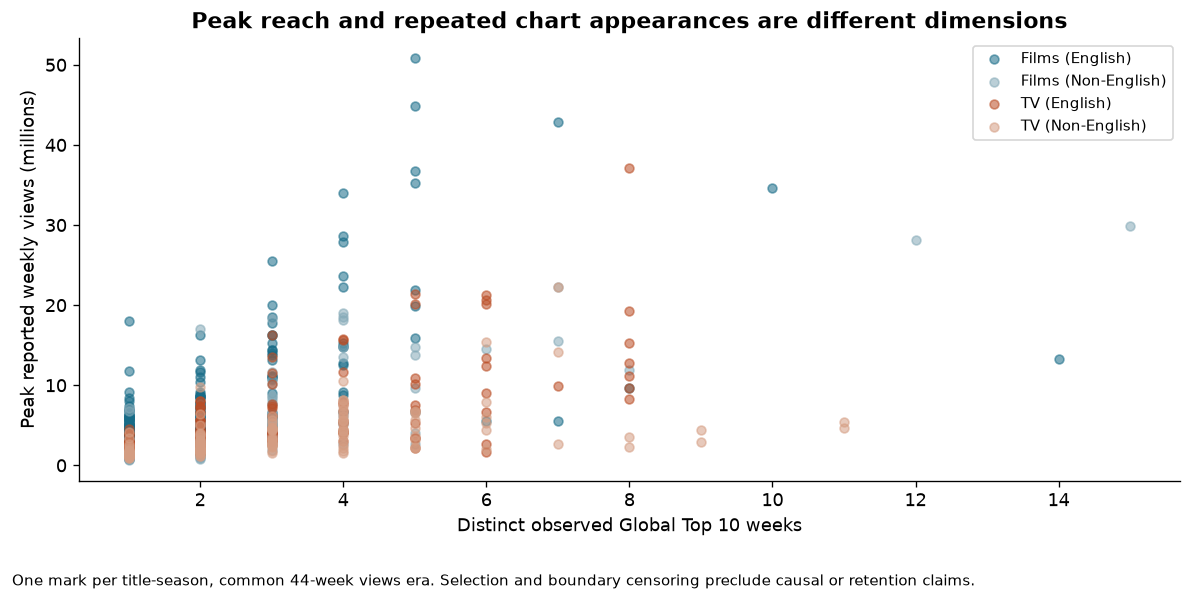

,category,display_title,views_first_91_days


In [5]:
# I display two dimensions without suggesting their product has a validated meaning.
plot_tradeoff(units)
plt.show()
display(most_popular[['category','display_title','views_first_91_days']])

### Visualization 4 interpretation
High peak views and many observed chart weeks are not interchangeable. The full 146-week snapshot's longest observed title-season has 30 Global Top 10 appearances; aggregating all seasons by show would distort that unit. The optional historical 91-day table is empty in this run and supplies no headline result. A current all-time list would answer a different question and is not substituted.

## 6. Conclusion, call to action, and ethics
Use separate reach, persistence, and country-breadth columns when reviewing a content slate. Compare like reporting periods and retain season identifiers. A diverse shortlist can include film peaks and repeated TV chart appearances, but this dataset cannot justify an investment budget without costs, availability, release timing, margins, and subscriber outcomes.

Direct labels, common windows, and zero-based bar axes make the visual story inspectable. The data cover Top 10 winners, not the full catalog. Category lists contain the same number of weekly positions, so higher mean persistence also implies fewer distinct charting entries. This is descriptive selection, not evidence that a language category universally performs better. The files end in April 2024 and must not be called current 2026 rankings.

## References
- Netflix. [Official Top 10 data and downloads](https://www.netflix.com/tudum/top10/). Current files downloaded October 28, 2026 and bounded to weeks ending April 14, 2024. Label revisions were retained. Bounded row counts and core metrics match the earlier supplied snapshot.
- Netflix. [Top 10 methodology](https://about.netflix.com/en/news/top-10-things-about-netflix-top-10), updated June 20, 2023. Retrieved October 28, 2026.

In [6]:
# I retain observed metrics and immutable source fingerprints for reproduction.
save_validation(metrics)
print('Analysis completed; validation.json records the source snapshot and actual results.')

Analysis completed; validation.json records the source snapshot and actual results.
